# Quadratic stellar limb darkening of the transit

The quadratic coefficients $(u_1, u_2)$ only shape the `batman` transit. The transit is identical in the point-source and extended-source models and cancels in every model comparison, so the coefficients have to be plausible, not precise. They are unrelated to the bolometric linear coefficient $u_{\rm B}$ of the irradiance, which weights the whole stellar spectrum and is much larger.

The NewEra cube of the pipeline (`NewEra/build_newera.ipynb`) holds disk-integrated fluxes $F_\lambda$ without an angular dependence, so it cannot give limb darkening. The coefficients are fitted with **ExoTiC-LD** (Grant & Wakeford 2024; `pip install exotic-ld`) to specific intensities $I(\mu)$ of its **PHOENIX** grid (same code family as NewEra and the same $T_{\rm eff}$ range down to 2300 K), with the 1D **MPS-ATLAS** grid (`mps1`, $T_{\rm eff} \geq 3500$ K) as a cross-check. Each host enters with its own $T_{\rm eff}$, log g and [Fe/H] from `PlanetParams`, as in the NewEra SED. The band weighting uses the throughput files of `Filters/Spiderman` over the integration ranges `filter_lambda`, i.e. exactly the bands of the forward model; ExoTiC-LD's intensities are photon rates and the throughputs electrons per photon, the same photon weighting as `fspiderman`. The fit excludes $\mu < 0.1$ (ExoTiC-LD default), where the intensity of spherical models drops steeply at the very limb.

The baseline is the median over the JWST bands and the twelve planets of the paper (PHOENIX grid). ExoTiC-LD downloads one model file per host and grid on first use into `astro_utils.LD_DATA` = `Stellar Model/ExoTiC-LD/` (gitignored). The fit itself is `astro_utils.quad_ld`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from HItargets_utils import hi_planets_by_name, instruments, PAPER_PLANETS, JWST_BANDS, DEFAULT_U, DEFAULT_U_B
from astro_utils import quad_ld, bolometric_ld_profile, LD_MU_MIN, LD_GRID_TEFF_MIN
from paper_plot_utils import paper_figure

PLANETS = hi_planets_by_name(PAPER_PLANETS)      # the twelve planets of the paper (tab:targets)
REF = hi_planets_by_name("TOI-2431 b")           # planet of the profile figure
BANDS = instruments()                            # all bands of the repo; Spitzer/IRAC2 is shown but not used for the baseline

LD_MODELS = ("phoenix", "mps1")                  # main grid (PHOENIX, T_eff 2300-15000 K) and cross-check (MPS-ATLAS 1D, T_eff 3500-9000 K)
MU_MIN = LD_MU_MIN                               # mu below which quad_ld does not fit (shaded in the profile figure)
U_B = DEFAULT_U_B                                # adopted bolometric linear coefficient of the irradiance, for comparison

In [2]:
rows, profiles_ref = [], {}
for ld_model in LD_MODELS:
    for planet in PLANETS.values():
        rows += quad_ld(planet, BANDS, ld_model)[0]
    profiles_ref[ld_model] = quad_ld(REF, BANDS, ld_model)[1]
ld = pd.DataFrame(rows)

flagged = ld[~(ld.in_grid & ld.covered)]
if len(flagged):
    print("outside the T_eff range or the wavelength range of the grid (excluded from baseline and comparison):")
    print(flagged[["ld_model", "planet", "T_eff", "band", "in_grid", "covered"]].to_string(index=False), "\n")

phoenix, TOI-2431 b, MIRI/F1280W: Wavelength range 115999.99999999999-140000.0 A has no overlap with stellar spectra's range 500.0-54999.0 A.
phoenix, TOI-2431 b, MIRI/F1500W: Wavelength range 135000.0-166000.0 A has no overlap with stellar spectra's range 500.0-54999.0 A.
phoenix, TOI-2431 b, MIRI/F1800W: Wavelength range 164999.99999999997-195000.0 A has no overlap with stellar spectra's range 500.0-54999.0 A.
phoenix, TOI-2260 b, MIRI/F1280W: Wavelength range 115999.99999999999-140000.0 A has no overlap with stellar spectra's range 500.0-54999.0 A.
phoenix, TOI-2260 b, MIRI/F1500W: Wavelength range 135000.0-166000.0 A has no overlap with stellar spectra's range 500.0-54999.0 A.
phoenix, TOI-2260 b, MIRI/F1800W: Wavelength range 164999.99999999997-195000.0 A has no overlap with stellar spectra's range 500.0-54999.0 A.
phoenix, Kepler-1340 b, MIRI/F1280W: Wavelength range 115999.99999999999-140000.0 A has no overlap with stellar spectra's range 500.0-54999.0 A.
phoenix, Kepler-1340 b,

In [3]:
ok = ld[ld.in_grid & ld.covered]
main = ok[(ok.ld_model == LD_MODELS[0]) & ok.band.isin(JWST_BANDS)]
u_base = np.round(main[["u1", "u2"]].median().values, 2)
print(f"baseline (u1, u2) = ({u_base[0]:.2f}, {u_base[1]:.2f})   median of {len(main)} planet-band pairs, {LD_MODELS[0]} grid, JWST bands")
print(f"adopted DEFAULT_U (HItargets_utils.py) = {DEFAULT_U}" + ("" if np.allclose(u_base, DEFAULT_U) else "   <- differs from this baseline: update DEFAULT_U"))
print(f"range: u1 {main.u1.min():.3f} to {main.u1.max():.3f}, u2 {main.u2.min():.3f} to {main.u2.max():.3f}, u1 + u2 {(main.u1 + main.u2).min():.3f} to {(main.u1 + main.u2).max():.3f}")

for c in ("u1", "u2"):
    print(f"\n{c} ({LD_MODELS[0]}):")
    print(ok[ok.ld_model == LD_MODELS[0]].pivot(index="planet", columns="band", values=c).round(3).to_string())

both = ok.pivot_table(index=["planet", "band"], columns="ld_model", values=["u1", "u2"]).dropna()
d = both.xs(LD_MODELS[0], axis=1, level=1) - both.xs(LD_MODELS[1], axis=1, level=1)
print(f"\n{LD_MODELS[0]} - {LD_MODELS[1]} over {len(d)} common planet-band pairs: median |du1| = {d.u1.abs().median():.3f}, "
      f"median |du2| = {d.u2.abs().median():.3f}, max |d(u1 + u2)| = {(d.u1 + d.u2).abs().max():.3f}")

baseline (u1, u2) = (0.09, 0.14)   median of 24 planet-band pairs, phoenix grid, JWST bands
adopted DEFAULT_U (HItargets_utils.py) = (0.09, 0.14)
range: u1 0.037 to 0.120, u2 0.090 to 0.195, u1 + u2 0.167 to 0.303

u1 (phoenix):
band              JWST_NIRSpec.G395H_NRS1  JWST_NIRSpec.G395H_NRS2  Spitzer/IRAC2
planet                                                                           
EPIC 206042996 c                    0.079                    0.061          0.061
K2-131 b                            0.111                    0.093          0.092
K2-141 b                            0.120                    0.103          0.102
K2-157 b                            0.107                    0.089          0.088
K2-183 b                            0.104                    0.087          0.086
KOI-1843.03                         0.069                    0.037          0.038
Kepler-1340 b                       0.092                    0.077          0.075
Kepler-78 b                      

## Bolometric limb darkening ($u_{\rm B}$)

The linear coefficient of the irradiance weights the whole stellar spectrum by energy, so it depends on the host but not on the instrument: one value per host and grid (`bolometric_ld_profile`, least squares over $\mu \geq 0.1$), to compare with the adopted $u_{\rm B}$. PHOENIX stops at 5.5 µm; the printed fraction of $\sigma T_{\rm eff}^4$ outside each grid's range shows what that misses.

In [4]:
bol = pd.DataFrame([dict(planet=pl.name, T_eff=pl.T2_eff, logg=pl.logg, ld_model=m, u_bol=u_bol, f_out=f_out)
                    for m in LD_MODELS for pl in PLANETS.values()
                    for _, _, u_bol, f_out in [bolometric_ld_profile(pl, m)]])
bol["in_grid"] = bol.T_eff >= bol.ld_model.map(LD_GRID_TEFF_MIN)

tab = bol.pivot(index="planet", columns="ld_model", values="u_bol")[list(LD_MODELS)]
tab = bol.groupby("planet")[["T_eff", "logg"]].first().join(tab).sort_values("T_eff")
print(f"bolometric linear coefficient per host (least squares over mu >= {MU_MIN}), adopted u_B = {U_B}:")
print(tab.round({"T_eff": 0, "logg": 2, **{m: 3 for m in LD_MODELS}}).to_string())

good = bol[bol.in_grid]
print("\nmedian over hosts: " + ", ".join(f"{m} {good[good.ld_model == m].u_bol.median():.3f}" for m in LD_MODELS))
print("largest fraction of sigma T_eff^4 outside the grid's wavelength range: "
      + ", ".join(f"{m} {100 * bol[bol.ld_model == m].f_out.max():.1f} %" for m in LD_MODELS))
if (~bol.in_grid).any():
    print("below the T_eff range of the grid (nearest model):", bol.loc[~bol.in_grid, ["ld_model", "planet", "T_eff"]].to_string(index=False))

bolometric linear coefficient per host (least squares over mu >= 0.1), adopted u_B = 0.5:
                   T_eff  logg  phoenix   mps1
planet                                        
KOI-1843.03       3584.0  4.80    0.350  0.414
TOI-2431 b        4109.0  4.68    0.485  0.495
EPIC 206042996 c  4114.0  4.80    0.421  0.495
K2-141 b          4599.0  4.62    0.563  0.562
Kepler-78 b       5058.0  4.61    0.570  0.560
K2-131 b          5120.0  4.61    0.570  0.564
K2-157 b          5334.0  4.45    0.570  0.563
TOI-561 b         5342.0  4.47    0.556  0.549
K2-183 b          5482.0  4.60    0.570  0.562
TOI-2260 b        5534.0  4.62    0.570  0.565
Kepler-990 c      5948.0  4.39    0.563  0.546
Kepler-1340 b     6331.0  4.24    0.572  0.534

median over hosts: phoenix 0.566, mps1 0.555
largest fraction of sigma T_eff^4 outside the grid's wavelength range: phoenix 1.5 %, mps1 0.0 %


## Intensity profiles of TOI-2431 b

Model intensities (points) and quadratic fits (lines) per band, with the baseline and, for contrast, the bolometric profile of the same grid (energy-weighted over all its wavelengths, gray squares) next to the linear law $u_{\rm B}$ of the irradiance. The shaded strip $\mu < 0.1$ is not fitted.

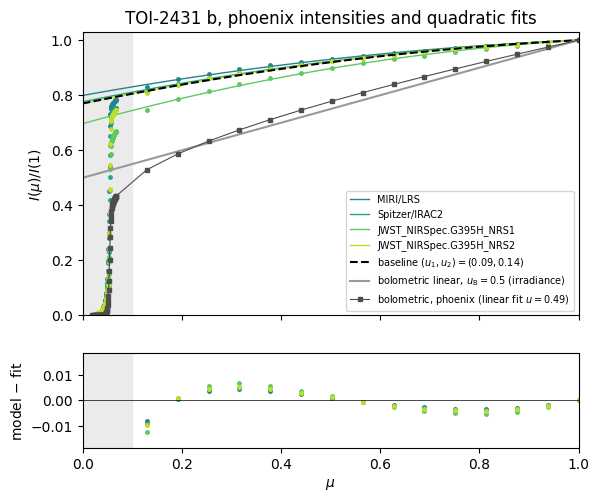

bolometric phoenix profile of TOI-2431 b: least-squares linear u = 0.485 (mu >= 0.1); 1.0 % of sigma T_eff^4 lies outside the grid's wavelength range


In [5]:
PAPER_MODE = False
quad = lambda mu, u: 1 - u[0] * (1 - mu) - u[1] * (1 - mu) ** 2
mu = np.linspace(0, 1, 300)
ref = ld[(ld.ld_model == LD_MODELS[0]) & (ld.planet == REF.name)].set_index("band")
colors = dict(zip(BANDS, plt.cm.viridis(np.linspace(0, 0.9, len(BANDS)))))

fig, (ax, axr) = plt.subplots(2, 1, figsize=(6.4, 5.4), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
r_max = 0.
for band, (m, I) in profiles_ref[LD_MODELS[0]].items():
    u = ref.loc[band, ["u1", "u2"]].values.astype(float)
    ax.plot(m, I, "o", ms=2.5, color=colors[band])
    ax.plot(mu, quad(mu, u), lw=1, color=colors[band], label=band)
    axr.plot(m, I - quad(m, u), "o", ms=2.5, color=colors[band])
    r_max = max(r_max, np.abs(I - quad(m, u))[m >= MU_MIN].max())
ax.plot(mu, quad(mu, u_base), "k--", lw=1.5, label=rf"baseline $(u_1, u_2) = ({u_base[0]:.2f}, {u_base[1]:.2f})$")
ax.plot(mu, 1 - U_B * (1 - mu), color="0.6", lw=1.5, label=rf"bolometric linear, $u_{{\rm B}} = {U_B}$ (irradiance)")
mu_bol, I_bol, u_bol, f_out = bolometric_ld_profile(REF, LD_MODELS[0])   # energy-weighted over the whole grid
ax.plot(mu_bol, I_bol, "s-", ms=2.5, lw=0.8, color="0.3", label=rf"bolometric, {LD_MODELS[0]} (linear fit $u = {u_bol:.2f}$)")
for a in (ax, axr):
    a.axvspan(0, MU_MIN, color="0.92", zorder=0)
axr.axhline(0, color="k", lw=0.5)
ax.set(ylabel=r"$I(\mu)/I(1)$", ylim=(0, 1.03), title=f"{REF.name}, {LD_MODELS[0]} intensities and quadratic fits")
axr.set(xlabel=r"$\mu$", ylabel="model $-$ fit", xlim=(0, 1), ylim=(-1.5 * r_max, 1.5 * r_max))
ax.legend(fontsize=7, loc="lower right")
paper_figure("ld_profiles_toi2431b", PAPER_MODE)
plt.show()
print(f"bolometric {LD_MODELS[0]} profile of {REF.name}: least-squares linear u = {u_bol:.3f} (mu >= {MU_MIN}); "
      f"{100 * f_out:.1f} % of sigma T_eff^4 lies outside the grid's wavelength range")

## Coefficients across the planets of the paper

Each point is one host and band (PHOENIX grid), colored by the host's $T_{\rm eff}$. A red edge marks a host below the $T_{\rm eff}$ range of the grid.

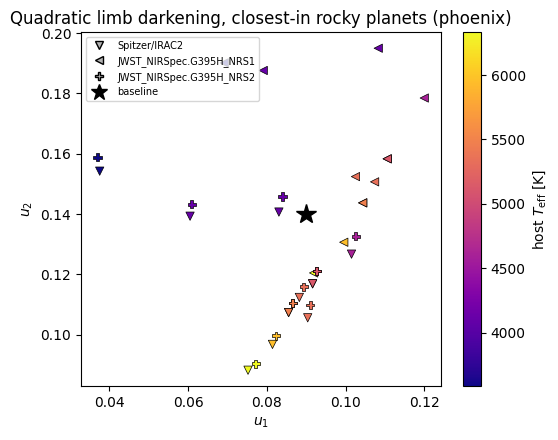

In [6]:
PAPER_MODE = False
markers = dict(zip(BANDS, "osD^v<P>"))
d = ld[(ld.ld_model == LD_MODELS[0]) & ld.covered]
fig, ax = plt.subplots(figsize=(5.8, 4.6))
for band, g in d.groupby("band"):
    sc = ax.scatter(g.u1, g.u2, c=g.T_eff, cmap="plasma", vmin=d.T_eff.min(), vmax=d.T_eff.max(), marker=markers[band],
                    s=36, edgecolors=np.where(g.in_grid, "k", "r"), linewidths=0.5)
ax.plot(*u_base, "k*", ms=15)
handles = [plt.Line2D([], [], marker=markers[b], ls="", color="0.7", mec="k", label=b) for b in BANDS if b in set(d.band)]
handles += [plt.Line2D([], [], marker="*", ls="", color="k", ms=12, label="baseline")]
ax.legend(handles=handles, fontsize=7)
fig.colorbar(sc, ax=ax, label=r"host $T_{\rm eff}$ [K]")
ax.set(xlabel="$u_1$", ylabel="$u_2$", title=f"Quadratic limb darkening, closest-in rocky planets ({LD_MODELS[0]})")
paper_figure("ld_coeffs_population", PAPER_MODE)
plt.show()